<a href="https://colab.research.google.com/github/PalQuisp/Sis420-int/blob/main/examen_1parcial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import soundfile as sf

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [13]:
import os
import librosa
import numpy as np

DATA_PATH = '/content/drive/MyDrive/machine learning/exam/wav'

files = []

for file in os.listdir(DATA_PATH):

    if file.endswith(".wav"):
        files.append(os.path.join(DATA_PATH, file))

print("Cantidad de audios:", len(files))

# Mostrar algunos archivos
for file in files[:5]:
    print(file)

Cantidad de audios: 535
/content/drive/MyDrive/machine learning/exam/wav/03a02Fc.wav
/content/drive/MyDrive/machine learning/exam/wav/03a02Nc.wav
/content/drive/MyDrive/machine learning/exam/wav/03a01Fa.wav
/content/drive/MyDrive/machine learning/exam/wav/03a02Wb.wav
/content/drive/MyDrive/machine learning/exam/wav/03a02Ta.wav


In [14]:
import pandas as pd

emotion_map = {
    "W": "Anger",
    "L": "Boredom",
    "E": "Disgust",
    "A": "Fear",
    "F": "Happiness",
    "T": "Sadness",
    "N": "Neutral"
}

data = []

for filepath in files:

    filename = os.path.basename(filepath)

    # Código de emoción
    emotion_code = filename[5]

    if emotion_code in emotion_map:

        data.append({
            "filepath": filepath,
            "filename": filename,
            "emotion": emotion_map[emotion_code]
        })

df = pd.DataFrame(data)

print(df.head())
print("\nCantidad de registros:", len(df))

                                            filepath     filename    emotion
0  /content/drive/MyDrive/machine learning/exam/w...  03a02Fc.wav  Happiness
1  /content/drive/MyDrive/machine learning/exam/w...  03a02Nc.wav    Neutral
2  /content/drive/MyDrive/machine learning/exam/w...  03a01Fa.wav  Happiness
3  /content/drive/MyDrive/machine learning/exam/w...  03a02Wb.wav      Anger
4  /content/drive/MyDrive/machine learning/exam/w...  03a02Ta.wav    Sadness

Cantidad de registros: 535


In [15]:
def get_emotion(filepath):

    filename = os.path.basename(filepath)

    # La letra de emoción está en la posición 5
    emotion_code = filename[5]

    return emotion_map.get(emotion_code)

In [16]:
print(get_emotion("03a02Ta.wav"))

Sadness


In [17]:
for f in files[:10]:
    print(os.path.basename(f), "->", get_emotion(f))

03a02Fc.wav -> Happiness
03a02Nc.wav -> Neutral
03a01Fa.wav -> Happiness
03a02Wb.wav -> Anger
03a02Ta.wav -> Sadness
03a01Nc.wav -> Neutral
03a01Wa.wav -> Anger
03b03Nb.wav -> Neutral
09a04La.wav -> Boredom
03b09Nc.wav -> Neutral


In [18]:
# 10. CREAR DATAFRAME

data = []

for filepath in files:

    emotion = get_emotion(filepath)

    if emotion is not None:

        data.append({
            "filepath": filepath,
            "filename": os.path.basename(filepath),
            "emotion": emotion
        })

df = pd.DataFrame(data)

print(df.head())
print("\nCantidad total:", len(df))

                                            filepath     filename    emotion
0  /content/drive/MyDrive/machine learning/exam/w...  03a02Fc.wav  Happiness
1  /content/drive/MyDrive/machine learning/exam/w...  03a02Nc.wav    Neutral
2  /content/drive/MyDrive/machine learning/exam/w...  03a01Fa.wav  Happiness
3  /content/drive/MyDrive/machine learning/exam/w...  03a02Wb.wav      Anger
4  /content/drive/MyDrive/machine learning/exam/w...  03a02Ta.wav    Sadness

Cantidad total: 535


In [19]:
# 11. DISTRIBUCIÓN DE CLASES
# ============================================================

print(df["emotion"].value_counts())

emotion
Anger        127
Boredom       81
Neutral       79
Happiness     71
Fear          69
Sadness       62
Disgust       46
Name: count, dtype: int64


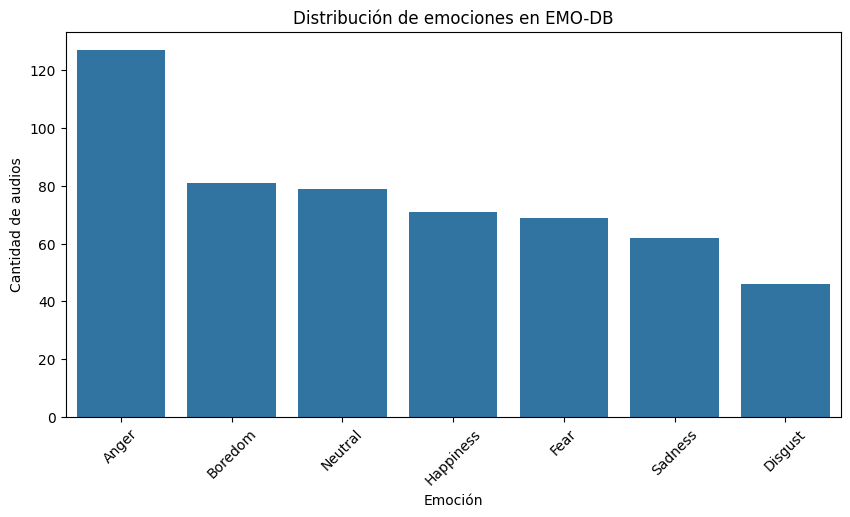

In [20]:
# 12. GRÁFICO DE DISTRIBUCIÓN
# ============================================================

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="emotion",
    order=df["emotion"].value_counts().index
)

plt.title("Distribución de emociones en EMO-DB")
plt.xlabel("Emoción")
plt.ylabel("Cantidad de audios")
plt.xticks(rotation=45)

plt.show()

In [21]:
# 13. SELECCIONAR UN AUDIO
# ============================================================

sample_file = df.iloc[0]["filepath"]

print("Archivo:", sample_file)
print("Emoción:", df.iloc[0]["emotion"])

Archivo: /content/drive/MyDrive/machine learning/exam/wav/03a02Fc.wav
Emoción: Happiness


In [22]:
sample_file = df.iloc[0]["filepath"]
audio, sr = librosa.load(
    sample_file,
    sr=16000
)

print("Frecuencia de muestreo:", sr)
print("Número de muestras:", len(audio))
print("Duración:", len(audio) / sr, "segundos")

#PRUEBA
print("Archivo:", sample_file)
print("¿Existe?:", os.path.exists(sample_file))

Frecuencia de muestreo: 16000
Número de muestras: 32100
Duración: 2.00625 segundos
Archivo: /content/drive/MyDrive/machine learning/exam/wav/03a02Fc.wav
¿Existe?: True


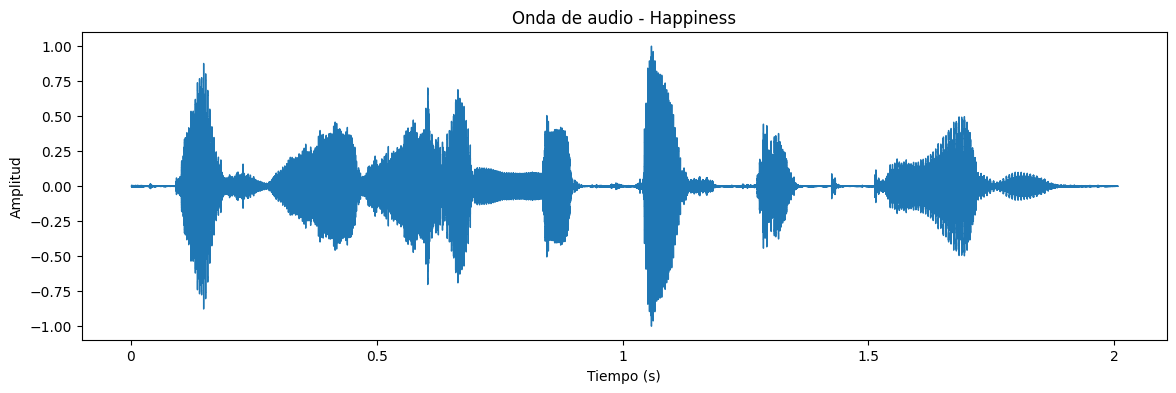

In [23]:
# 14. FORMA DE ONDA
# ============================================================

plt.figure(figsize=(14, 4))

librosa.display.waveshow(
    audio,
    sr=sr
)

plt.title(
    f"Onda de audio - {df.iloc[0]['emotion']}"
)

plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")

plt.show()

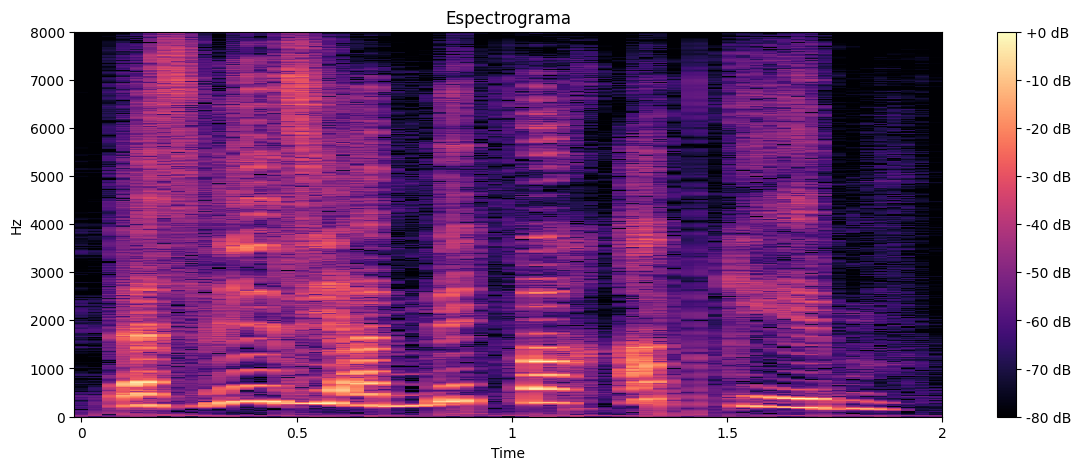

In [24]:
# 15. ESPECTROGRAMA
# ============================================================

D = librosa.stft(audio)

S_db = librosa.amplitude_to_db(
    np.abs(D),
    ref=np.max
)

plt.figure(figsize=(14, 5))

librosa.display.specshow(
    S_db,
    sr=sr,
    x_axis="time",
    y_axis="hz"
)

plt.colorbar(format="%+2.0f dB")

plt.title("Espectrograma")

plt.show()

In [25]:
# 16. EXTRACCIÓN DE MFCC
# ============================================================

def extract_features(filepath):

    audio, sr = librosa.load(
        filepath,
        sr=16000
    )

    # MFCC
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13
    )

    # Media
    mfcc_mean = np.mean(
        mfcc,
        axis=1
    )

    # Desviación estándar
    mfcc_std = np.std(
        mfcc,
        axis=1
    )

    # Concatenar
    features = np.concatenate([
        mfcc_mean,
        mfcc_std
    ])

    return features

In [26]:
features = extract_features(sample_file)

print("Número de características:", len(features))
print(features)

Número de características: 26
[-210.08412     54.724594    -7.3475127   10.08759     -3.4360778
   -1.8587675  -14.699742    -9.550004   -16.177086    -4.2048197
   -9.786841    -5.0944395  -11.831728   112.077255    40.722393
   22.86532     30.023912    22.163813    22.627636    19.878557
   13.240652    14.941352    14.959037     8.984687    11.866087
    9.474418 ]


In [27]:
# 17. EXTRAER CARACTERÍSTICAS DE TODO EL DATASET
# ============================================================

X = []
y = []

for _, row in df.iterrows():

    filepath = row["filepath"]
    emotion = row["emotion"]

    try:
        features = extract_features(filepath)

        X.append(features)
        y.append(emotion)

    except Exception as e:
        print(f"Error en: {filepath}")
        print(e)

X = np.array(X)
y = np.array(y)

print("Shape de X:", X.shape)
print("Shape de y:", y.shape)

Shape de X: (535, 26)
Shape de y: (535,)


In [28]:
# 18. COMPROBAR VALORES FALTANTES
# ============================================================

print("NaN en X:", np.isnan(X).sum())
print("Infinitos en X:", np.isinf(X).sum())

NaN en X: 0
Infinitos en X: 0


In [29]:
# 19. CODIFICAR ETIQUETAS
# ============================================================

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Clases:")

for i, class_name in enumerate(label_encoder.classes_):

    print(i, "->", class_name)

Clases:
0 -> Anger
1 -> Boredom
2 -> Disgust
3 -> Fear
4 -> Happiness
5 -> Neutral
6 -> Sadness


In [30]:
# 20. TRAIN / VALIDATION / TEST
# ============================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (374, 26)
Validation: (80, 26)
Test: (81, 26)


In [31]:
# 21. NORMALIZACIÓN
# ============================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)

X_test = scaler.transform(X_test)

In [32]:
# 22. CONVERTIR A TENSORES
# ============================================================

X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

In [33]:
# 23. DATALOADER
# ============================================================

batch_size = 32

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [34]:
# 24. RED NEURONAL
# ============================================================

class AudioClassifier(nn.Module):

    def __init__(
        self,
        input_size,
        num_classes
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                input_size,
                64
            ),

            nn.ReLU(),

            nn.Dropout(
                0.30
            ),

            nn.Linear(
                64,
                32
            ),

            nn.ReLU(),

            nn.Dropout(
                0.20
            ),

            nn.Linear(
                32,
                num_classes
            )
        )

    def forward(self, x):

        return self.network(x)

In [35]:
# 25. CREAR MODELO
# ============================================================

input_size = X_train.shape[1]

num_classes = len(
    label_encoder.classes_
)

model = AudioClassifier(
    input_size,
    num_classes
)

print(model)

AudioClassifier(
  (network): Sequential(
    (0): Linear(in_features=26, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=7, bias=True)
  )
)


In [36]:
nn.CrossEntropyLoss()
nn.Linear(32, 7)

Linear(in_features=32, out_features=7, bias=True)

In [37]:
# 26. LOSS
# ============================================================

criterion = nn.CrossEntropyLoss()

In [38]:
# 27. OPTIMIZADOR
# ============================================================

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

In [39]:
# 28. ENTRENAMIENTO
# ============================================================

epochs = 100

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")

patience = 10

counter = 0

best_model_state = None

In [40]:
# 29. LOOP DE ENTRENAMIENTO
# ============================================================

for epoch in range(epochs):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    model.train()

    running_loss = 0.0

    correct = 0
    total = 0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(
            outputs,
            y_batch
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item()
            * X_batch.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += y_batch.size(0)

        correct += (
            predicted == y_batch
        ).sum().item()

    train_loss = (
        running_loss / total
    )

    train_accuracy = (
        correct / total
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    model.eval()

    val_running_loss = 0.0

    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            outputs = model(X_batch)

            loss = criterion(
                outputs,
                y_batch
            )

            val_running_loss += (
                loss.item()
                * X_batch.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            val_total += y_batch.size(0)

            val_correct += (
                predicted == y_batch
            ).sum().item()

    val_loss = (
        val_running_loss / val_total
    )

    val_accuracy = (
        val_correct / val_total
    )

    # Guardar resultados
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(
        train_accuracy
    )

    val_accuracies.append(
        val_accuracy
    )

    # --------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        counter = 0

        best_model_state = (
            model.state_dict()
        )

    else:

        counter += 1

    # Mostrar resultados

    print(
        f"Epoch [{epoch+1:03d}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    if counter >= patience:

        print(
            "\nEarly stopping activado."
        )

        break

Epoch [001/100] Train Loss: 1.9434 Val Loss: 1.9020 Train Acc: 0.1524 Val Acc: 0.1750
Epoch [002/100] Train Loss: 1.8733 Val Loss: 1.8137 Train Acc: 0.2567 Val Acc: 0.4500
Epoch [003/100] Train Loss: 1.7800 Val Loss: 1.6980 Train Acc: 0.3877 Val Acc: 0.4250
Epoch [004/100] Train Loss: 1.6595 Val Loss: 1.5628 Train Acc: 0.4251 Val Acc: 0.4000
Epoch [005/100] Train Loss: 1.5414 Val Loss: 1.4528 Train Acc: 0.4198 Val Acc: 0.4250
Epoch [006/100] Train Loss: 1.4517 Val Loss: 1.3811 Train Acc: 0.4171 Val Acc: 0.4375
Epoch [007/100] Train Loss: 1.3805 Val Loss: 1.3329 Train Acc: 0.4599 Val Acc: 0.4750
Epoch [008/100] Train Loss: 1.3169 Val Loss: 1.2919 Train Acc: 0.4840 Val Acc: 0.4875
Epoch [009/100] Train Loss: 1.2705 Val Loss: 1.2492 Train Acc: 0.5027 Val Acc: 0.5000
Epoch [010/100] Train Loss: 1.2213 Val Loss: 1.2004 Train Acc: 0.5241 Val Acc: 0.5375
Epoch [011/100] Train Loss: 1.1498 Val Loss: 1.1607 Train Acc: 0.5508 Val Acc: 0.5750
Epoch [012/100] Train Loss: 1.1633 Val Loss: 1.1182 Tr

In [41]:
# 30. CARGAR MEJOR MODELO
# ============================================================

if best_model_state is not None:

    model.load_state_dict(
        best_model_state
    )

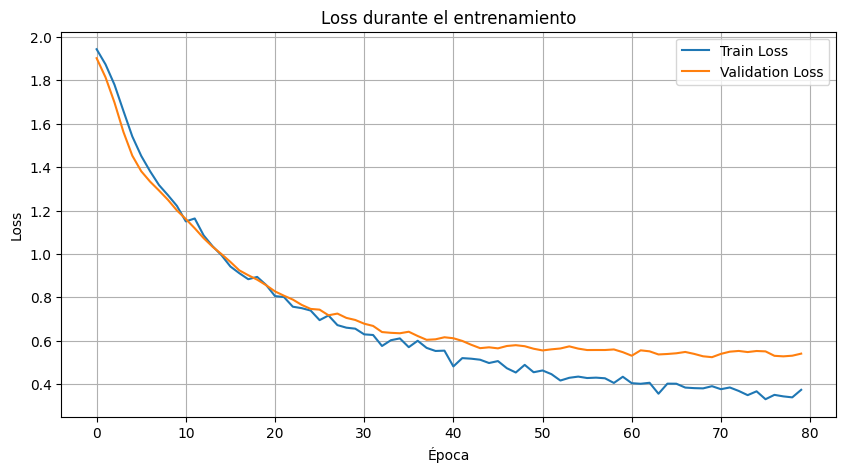

In [42]:
# 31. GRÁFICA DE LOSS
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    train_losses,
    label="Train Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.title(
    "Loss durante el entrenamiento"
)

plt.xlabel("Época")
plt.ylabel("Loss")

plt.legend()

plt.grid()

plt.show()

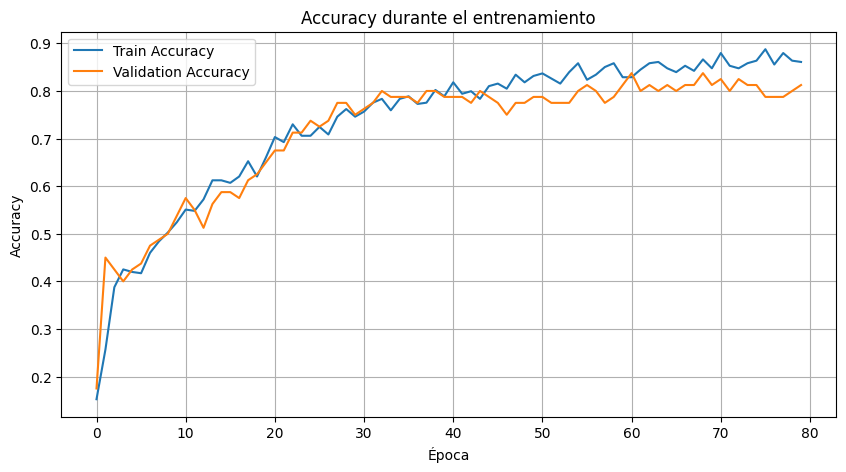

In [43]:
# 32. GRÁFICA DE ACCURACY
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    train_accuracies,
    label="Train Accuracy"
)

plt.plot(
    val_accuracies,
    label="Validation Accuracy"
)

plt.title(
    "Accuracy durante el entrenamiento"
)

plt.xlabel("Época")
plt.ylabel("Accuracy")

plt.legend()

plt.grid()

plt.show()

In [44]:
# 33. PREDICCIONES SOBRE TEST
# ============================================================

model.eval()

with torch.no_grad():

    outputs = model(
        X_test_tensor
    )

    probabilities = torch.softmax(
        outputs,
        dim=1
    )

    _, predictions = torch.max(
        probabilities,
        1
    )

y_pred = predictions.numpy()

In [45]:
# 34. ACCURACY
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    f"Accuracy: {accuracy:.4f}"
)

print(
    f"Accuracy: {accuracy*100:.2f}%"
)

Accuracy: 0.7160
Accuracy: 71.60%


In [46]:
# 35. PRECISION
# ============================================================

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print(
    f"Precision: {precision:.4f}"
)

Precision: 0.7356


In [47]:
# 36. RECALL
# ============================================================

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print(
    f"Recall: {recall:.4f}"
)

Recall: 0.7160


In [48]:
# 37. F1-SCORE
# ============================================================

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print(
    f"F1-score: {f1:.4f}"
)

F1-score: 0.7181


In [49]:
# 38. RESUMEN DE MÉTRICAS
# ============================================================

metrics = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],

    "Valor": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

metrics

,Métrica,Valor
0,Accuracy,0.716049
1,Precision,0.735638
2,Recall,0.716049
3,F1-score,0.718051


In [50]:
# 39. CLASSIFICATION REPORT
# ============================================================

print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       Anger       0.78      0.95      0.86        19
     Boredom       0.50      0.58      0.54        12
     Disgust       1.00      0.86      0.92         7
        Fear       0.78      0.64      0.70        11
   Happiness       0.70      0.64      0.67        11
     Neutral       0.54      0.58      0.56        12
     Sadness       1.00      0.67      0.80         9

    accuracy                           0.72        81
   macro avg       0.76      0.70      0.72        81
weighted avg       0.74      0.72      0.72        81



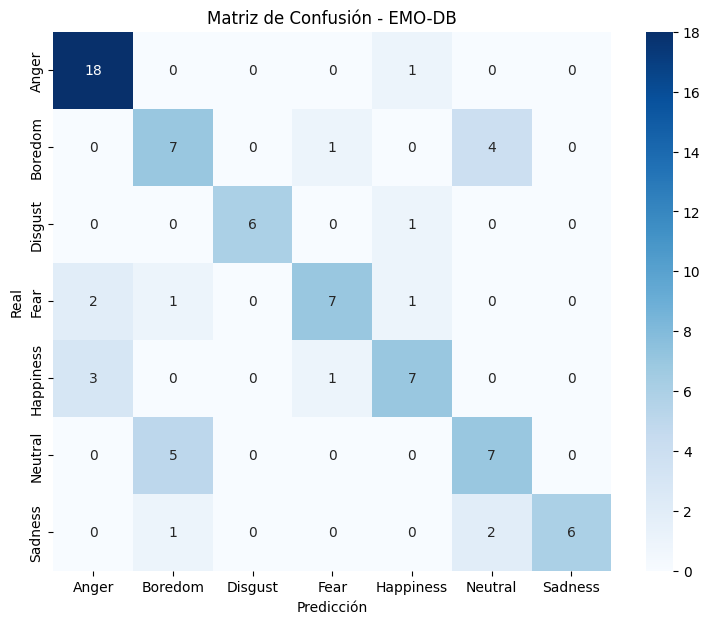

In [51]:
# 40. MATRIZ DE CONFUSIÓN
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(
    "Matriz de Confusión - EMO-DB"
)

plt.xlabel(
    "Predicción"
)

plt.ylabel(
    "Real"
)

plt.show()

In [52]:
# 41. PROBABILIDADES DE UNA MUESTRA
# ============================================================

sample_index = 0

sample = X_test_tensor[
    sample_index
].unsqueeze(0)

model.eval()

with torch.no_grad():

    output = model(sample)

    probs = torch.softmax(
        output,
        dim=1
    )

probs = probs.numpy()[0]

for class_name, probability in zip(
    label_encoder.classes_,
    probs
):

    print(
        f"{class_name}: "
        f"{probability:.4f}"
    )

Anger: 0.4003
Boredom: 0.0006
Disgust: 0.0361
Fear: 0.1481
Happiness: 0.4133
Neutral: 0.0017
Sadness: 0.0000


In [53]:
# 42. FUNCIÓN DE PREDICCIÓN
# ============================================================

def predict_audio(filepath):

    # Extraer características
    features = extract_features(
        filepath
    )

    # Normalizar
    features = scaler.transform(
        [features]
    )

    # Convertir a tensor
    tensor = torch.tensor(
        features,
        dtype=torch.float32
    )

    # Predicción
    model.eval()

    with torch.no_grad():

        output = model(tensor)

        probabilities = torch.softmax(
            output,
            dim=1
        )

        predicted_class = torch.argmax(
            probabilities,
            dim=1
        ).item()

    emotion = (
        label_encoder
        .inverse_transform(
            [predicted_class]
        )[0]
    )

    return emotion, probabilities.numpy()[0]

In [54]:
# 43. PROBAR UN AUDIO
# ============================================================

test_audio = df.iloc[10]["filepath"]

emotion, probabilities = predict_audio(
    test_audio
)

print(
    "Archivo:",
    os.path.basename(test_audio)
)

print(
    "Emoción predicha:",
    emotion
)

print("\nProbabilidades:")

for class_name, probability in zip(
    label_encoder.classes_,
    probabilities
):

    print(
        f"{class_name}: "
        f"{probability:.4f}"
    )

Archivo: 10b09Wb.wav
Emoción predicha: Anger

Probabilidades:
Anger: 0.9065
Boredom: 0.0000
Disgust: 0.0002
Fear: 0.0003
Happiness: 0.0929
Neutral: 0.0000
Sadness: 0.0000
